In [1]:

# Step 1: Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import scipy.stats as stats

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving hotel_bookings (1).csv to hotel_bookings (1) (1).csv


In [3]:

# Loading the hotel booking dataset

df = pd.read_csv("hotel_bookings (1).csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [4]:

# Loading the hotel booking dataset

df = pd.read_csv("hotel_bookings (1).csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [5]:

df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [6]:

print("Dataset successfully loaded")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset successfully loaded
Number of rows: 119390
Number of columns: 32


In [7]:

# Step 2.1: Check the shape of the dataset

print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Dataset Shape: (119390, 32)
Total Rows: 119390
Total Columns: 32


In [8]:

# Step 2.2: Display column names

print("Column Names:")
print(df.columns)


Column Names:
Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')


In [9]:

# Step 2.3: Check the index

print("Dataset Index:")
print(df.index)


Dataset Index:
RangeIndex(start=0, stop=119390, step=1)


In [10]:

# Step 2.4: Check data types

print("Data Types of Each Column:")
print(df.dtypes)


Data Types of Each Column:
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent  

In [11]:

# Step 2.5: Classify variables

numerical_cols = [
    'is_canceled',
    'lead_time',
    'arrival_date_year',
    'arrival_date_week_number',
    'arrival_date_day_of_month',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'is_repeated_guest',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'booking_changes',
    'days_in_waiting_list',
    'adr',
    'required_car_parking_spaces',
    'total_of_special_requests'
]

categorical_cols = [
    'hotel',
    'arrival_date_month',
    'meal',
    'country',
    'market_segment',
    'distribution_channel',
    'reserved_room_type',
    'assigned_room_type',
    'deposit_type',
    'customer_type',
    'reservation_status'
]

date_cols = ['reservation_status_date']

id_cols = ['agent', 'company']

print("Numerical Columns:", len(numerical_cols))
print(numerical_cols)

print("\nCategorical Columns:", len(categorical_cols))
print(categorical_cols)

print("\nDate Columns:", date_cols)

print("\nIdentifier/Code Columns:", id_cols)


Numerical Columns: 18
['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical Columns: 11
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status']

Date Columns: ['reservation_status_date']

Identifier/Code Columns: ['agent', 'company']


In [12]:

# Step 2.6: Creating variables

total_bookings = df.shape[0]

total_columns = df.shape[1]

hotel_name = "Hotel Booking Demand"

cancellation_rate = df['is_canceled'].mean() * 100

# Display variables

print("Dataset Name:", hotel_name)
print("Total Bookings:", total_bookings)
print("Total Columns:", total_columns)
print("Cancellation Rate:", round(cancellation_rate, 2), "%")

# Check variable data types

print("\nData Types:")
print(type(total_bookings))
print(type(hotel_name))
print(type(cancellation_rate))


Dataset Name: Hotel Booking Demand
Total Bookings: 119390
Total Columns: 32
Cancellation Rate: 37.04 %

Data Types:
<class 'int'>
<class 'str'>
<class 'numpy.float64'>


In [13]:

# Step 2.7: Arithmetic operators

total_bookings = df.shape[0]

total_cancellations = df['is_canceled'].sum()

successful_bookings = total_bookings - total_cancellations

cancellation_percentage = (
    total_cancellations / total_bookings
) * 100

print("Total Bookings:", total_bookings)

print("Total Cancellations:", total_cancellations)

print("Successful Bookings:", successful_bookings)

print("Cancellation Percentage:",
      round(cancellation_percentage, 2), "%")


Total Bookings: 119390
Total Cancellations: 44224
Successful Bookings: 75166
Cancellation Percentage: 37.04 %


In [14]:

# Step 3.1: Creating a function

def calculate_cancellation_rate(data):

    total = len(data)

    cancelled = data['is_canceled'].sum()

    rate = (cancelled / total) * 100

    return round(rate, 2)


# Calling the function

result = calculate_cancellation_rate(df)

print("Hotel Cancellation Rate:", result, "%")


Hotel Cancellation Rate: 37.04 %


In [15]:

# Step 3.2: Creating a list of important variables

hotel_variables = [
    'hotel',
    'is_canceled',
    'lead_time',
    'adr',
    'market_segment',
    'customer_type'
]

print("Important Hotel Variables:")
print(hotel_variables)

print("\nTotal Variables:", len(hotel_variables))


Important Hotel Variables:
['hotel', 'is_canceled', 'lead_time', 'adr', 'market_segment', 'customer_type']

Total Variables: 6


In [16]:

# Step 3.3: Creating a dictionary

hotel_information = {

    'Dataset': 'Hotel Booking Demand',

    'Total Bookings': df.shape[0],

    'Total Columns': df.shape[1],

    'Hotel Types': df['hotel'].nunique(),

    'Total Cancellations': df['is_canceled'].sum()

}

print("Hotel Dataset Information:")

for key, value in hotel_information.items():

    print(key, ":", value)


Hotel Dataset Information:
Dataset : Hotel Booking Demand
Total Bookings : 119390
Total Columns : 32
Hotel Types : 2
Total Cancellations : 44224


In [17]:

# Step 3.4: NumPy array

booking_values = np.array([
    100, 200, 300, 400, 500
])

print("Original Array:")
print(booking_values)

print("\nAddition:")
print(booking_values + 10)

print("\nMultiplication:")
print(booking_values * 2)

print("\nMean:")
print(np.mean(booking_values))

print("\nMaximum:")
print(np.max(booking_values))

print("\nMinimum:")
print(np.min(booking_values))


Original Array:
[100 200 300 400 500]

Addition:
[110 210 310 410 510]

Multiplication:
[ 200  400  600  800 1000]

Mean:
300.0

Maximum:
500

Minimum:
100


In [18]:

# Step 3.5: Creating a Pandas Series

lead_time_series = pd.Series(df['lead_time'])

print("Lead Time Series:")
print(lead_time_series.head())

print("\nAverage Lead Time:",
      lead_time_series.mean())

print("\nMaximum Lead Time:",
      lead_time_series.max())


Lead Time Series:
0    342
1    737
2      7
3     13
4     14
Name: lead_time, dtype: int64

Average Lead Time: 104.01141636652986

Maximum Lead Time: 737


In [19]:

# Step 3.6: Selecting important columns

hotel_analysis = df[
    ['hotel',
     'is_canceled',
     'lead_time',
     'adr',
     'market_segment',
     'customer_type']
]

print("Selected Hotel Data:")
display(hotel_analysis.head(10))


Selected Hotel Data:


,hotel,is_canceled,lead_time,adr,market_segment,customer_type
0,Resort Hotel,0,342,0.0,Direct,Transient
1,Resort Hotel,0,737,0.0,Direct,Transient
2,Resort Hotel,0,7,75.0,Direct,Transient
3,Resort Hotel,0,13,75.0,Corporate,Transient
4,Resort Hotel,0,14,98.0,Online TA,Transient
5,Resort Hotel,0,14,98.0,Online TA,Transient
6,Resort Hotel,0,0,107.0,Direct,Transient
7,Resort Hotel,0,9,103.0,Direct,Transient
8,Resort Hotel,1,85,82.0,Online TA,Transient
9,Resort Hotel,1,75,105.5,Offline TA/TO,Transient


In [20]:

# Step 4.1: View first 10 records

df.head(10)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,0.0,0,FB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,2015-07-03
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,82.0,0,1,Canceled,2015-05-06
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,D,D,0,No Deposit,15.0,NaN,0,Transient,105.5,0,0,Canceled,2015-04-22


In [21]:

# Step 4.2: View last 10 records

df.tail(10)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119380,City Hotel,0,44,2017,August,35,31,1,3,2,0.0,0,SC,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,140.75,0,1,Check-Out,2017-09-04
119381,City Hotel,0,188,2017,August,35,31,2,3,2,0.0,0,BB,DEU,Direct,Direct,0,0,0,A,A,0,No Deposit,14.0,NaN,0,Transient,99.00,0,0,Check-Out,2017-09-05
119382,City Hotel,0,135,2017,August,35,30,2,4,3,0.0,0,BB,JPN,Online TA,TA/TO,0,0,0,G,G,0,No Deposit,7.0,NaN,0,Transient,209.00,0,0,Check-Out,2017-09-05
119383,City Hotel,0,164,2017,August,35,31,2,4,2,0.0,0,BB,DEU,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,42.0,NaN,0,Transient,87.60,0,0,Check-Out,2017-09-06
119384,City Hotel,0,21,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,2,Check-Out,2017-09-06
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,0.0,0,HB,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [22]:

# Step 4.3: Random sampling

df.sample(10, random_state=42)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
30946,Resort Hotel,0,203,2016,December,49,2,2,5,2,0.0,0,BB,GBR,Direct,Direct,0,0,0,F,F,4,No Deposit,250.0,NaN,0,Transient,66.80,0,0,Check-Out,2016-12-09
40207,City Hotel,1,82,2015,July,29,16,0,3,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,76.50,0,0,Canceled,2015-07-16
103708,City Hotel,0,25,2016,December,53,27,0,3,3,0.0,0,BB,BRA,Offline TA/TO,TA/TO,0,0,0,A,K,2,No Deposit,220.0,NaN,0,Transient-Party,60.00,0,1,Check-Out,2016-12-30
85144,City Hotel,0,1,2016,March,11,9,0,1,1,0.0,0,BB,SWE,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient-Party,95.00,0,0,Check-Out,2016-03-10
109991,City Hotel,0,70,2017,April,16,16,2,2,2,0.0,0,SC,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,108.00,0,0,Check-Out,2017-04-20
110622,City Hotel,0,170,2017,April,17,27,0,3,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,130.50,0,0,Check-Out,2017-04-30
47790,City Hotel,1,21,2016,March,10,4,0,1,1,0.0,0,BB,SVN,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient-Party,85.00,0,0,Canceled,2016-02-26
44992,City Hotel,0,102,2015,October,42,16,0,2,2,0.0,0,HB,DEU,Offline TA/TO,TA/TO,0,0,0,A,D,0,No Deposit,6.0,NaN,0,Transient-Party,109.00,0,0,Check-Out,2015-10-18
30528,Resort Hotel,0,55,2016,November,47,19,2,5,2,0.0,0,HB,GBR,Online TA,TA/TO,0,0,0,D,D,1,No Deposit,314.0,NaN,0,Transient,67.44,0,0,Check-Out,2016-11-26
16886,Resort Hotel,0,222,2015,September,38,14,1,1,2,0.0,0,HB,ESP,Groups,TA/TO,0,0,0,A,A,0,No Deposit,68.0,NaN,0,Transient,80.00,0,0,Check-Out,2015-09-16


In [23]:

# Step 4.4: Complete dataset information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [24]:

# Step 4.5: Statistical summary

df.describe()


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [25]:

# Step 4.6: Categorical summary

df.describe(include='object')


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [26]:

# Step 5.1: Missing values

print("Missing Values in Each Column:")

print(df.isnull().sum())


Missing Values in Each Column:
hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                     

In [27]:

# Step 5.2: Columns with missing values

missing = df.isnull().sum()

missing_columns = missing[missing > 0]

print("Columns Having Missing Values:")

print(missing_columns)


Columns Having Missing Values:
children         4
country        488
agent        16340
company     112593
dtype: int64


In [28]:

# Step 5.3: Missing value percentage

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_summary = pd.DataFrame({

    'Missing Values': df.isnull().sum(),

    'Missing Percentage': missing_percentage.round(2)

})

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
]

display(missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
))


,Missing Values,Missing Percentage
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [29]:

# Step 5.4: Total missing cells

total_missing = df.isnull().sum().sum()

total_cells = df.size

missing_percent = (total_missing / total_cells) * 100

print("Total Missing Cells:", total_missing)

print("Total Dataset Cells:", total_cells)

print("Missing Percentage:",
      round(missing_percent, 2), "%")


Total Missing Cells: 129425
Total Dataset Cells: 3820480
Missing Percentage: 3.39 %


In [30]:

# Step 5.5: Identify duplicate records

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

print("Original Dataset Rows:", len(df))


Total Duplicate Records: 31994
Original Dataset Rows: 119390


In [31]:

# Step 6.1: Create a backup

raw = df.copy()

print("Original Dataset Shape:", raw.shape)

print("Original Missing Values:",
      raw.isnull().sum().sum())

print("Original Duplicate Records:",
      raw.duplicated().sum())


Original Dataset Shape: (119390, 32)
Original Missing Values: 129425
Original Duplicate Records: 31994


In [32]:

# Step 6.2: Create a working dataset

df_clean = raw.copy()

print("Working Dataset Created Successfully")

print("Shape:", df_clean.shape)


Working Dataset Created Successfully
Shape: (119390, 32)


In [33]:

# Step 6.3: Remove duplicate rows

duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates()

duplicates_after = df_clean.duplicated().sum()

print("Duplicates Before Cleaning:",
      duplicates_before)

print("Duplicates After Cleaning:",
      duplicates_after)

print("Rows After Removing Duplicates:",
      len(df_clean))


Duplicates Before Cleaning: 31994
Duplicates After Cleaning: 0
Rows After Removing Duplicates: 87396


In [34]:

# Step 6.4: Compare before and after cleaning

comparison = pd.DataFrame({

    'Measure': [
        'Total Rows',
        'Total Columns',
        'Duplicate Records',
        'Missing Cells'
    ],

    'Before Cleaning': [
        raw.shape[0],
        raw.shape[1],
        raw.duplicated().sum(),
        raw.isnull().sum().sum()
    ],

    'After Cleaning': [
        df_clean.shape[0],
        df_clean.shape[1],
        df_clean.duplicated().sum(),
        df_clean.isnull().sum().sum()
    ]

})

display(comparison)


,Measure,Before Cleaning,After Cleaning
0,Total Rows,119390,87396
1,Total Columns,32,32
2,Duplicate Records,31994,0
3,Missing Cells,129425,94786


In [35]:

# Step 6.5: Experiment with dropna()

df_drop = df_clean.dropna()

print("Rows Before dropna():", len(df_clean))

print("Rows After dropna():", len(df_drop))

data_lost = (
    (1 - len(df_drop) / len(df_clean)) * 100
)

print("Percentage of Data Lost:",
      round(data_lost, 2), "%")

print("Missing Values After dropna():",
      df_drop.isnull().sum().sum())


Rows Before dropna(): 87396
Rows After dropna(): 189
Percentage of Data Lost: 99.78 %
Missing Values After dropna(): 0


In [36]:

# Step 6.6: Create a copy for missing value treatment

df_final = df_clean.copy()

print("Missing Values Before Treatment:")

print(df_final.isnull().sum())


Missing Values Before Treatment:
hotel                                 0
is_canceled                           0
lead_time                             0
arrival_date_year                     0
arrival_date_month                    0
arrival_date_week_number              0
arrival_date_day_of_month             0
stays_in_weekend_nights               0
stays_in_week_nights                  0
adults                                0
children                              4
babies                                0
meal                                  0
country                             452
market_segment                        0
distribution_channel                  0
is_repeated_guest                     0
previous_cancellations                0
previous_bookings_not_canceled        0
reserved_room_type                    0
assigned_room_type                    0
booking_changes                       0
deposit_type                          0
agent                             12193
company

In [37]:

# Step 6.7: Fill missing children values

children_mode = df_final['children'].mode()[0]

df_final['children'] = df_final['children'].fillna(
    children_mode
)

print("Children Mode:", children_mode)

print("Missing Children Values:",
      df_final['children'].isnull().sum())


Children Mode: 0.0
Missing Children Values: 0


In [38]:

# Step 6.8: Handle missing country values

df_final['country'] = df_final['country'].fillna(
    'Unknown'
)

print("Missing Country Values:",
      df_final['country'].isnull().sum())

print("\nCountry Categories:")

print(df_final['country'].value_counts().head(10))


Missing Country Values: 0

Country Categories:
country
PRT    27453
GBR    10433
FRA     8837
ESP     7252
DEU     5387
ITA     3066
IRL     3016
BEL     2081
BRA     1995
NLD     1911
Name: count, dtype: int64


In [39]:

# Step 6.9: Handle missing agent and company IDs

df_final['agent'] = df_final['agent'].fillna(-1)

df_final['company'] = df_final['company'].fillna(-1)

print("Missing Agent Values:",
      df_final['agent'].isnull().sum())

print("Missing Company Values:",
      df_final['company'].isnull().sum())

print("\nUnrecorded Agent IDs:",
      (df_final['agent'] == -1).sum())

print("Unrecorded Company IDs:",
      (df_final['company'] == -1).sum())


Missing Agent Values: 0
Missing Company Values: 0

Unrecorded Agent IDs: 12193
Unrecorded Company IDs: 82137


In [40]:

# Step 6.10: Check missing values after treatment

print("Missing Values After Cleaning:")

print(df_final.isnull().sum())

print("\nTotal Missing Cells:")

print(df_final.isnull().sum().sum())

print("\nFinal Dataset Shape:")

print(df_final.shape)


Missing Values After Cleaning:
hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                    

In [41]:

# Step 6.11: Final cleaning comparison

cleaning_summary = pd.DataFrame({

    'Measure': [
        'Rows',
        'Columns',
        'Missing Cells',
        'Duplicate Rows'
    ],

    'Before Cleaning': [
        raw.shape[0],
        raw.shape[1],
        raw.isnull().sum().sum(),
        raw.duplicated().sum()
    ],

    'After Cleaning': [
        df_final.shape[0],
        df_final.shape[1],
        df_final.isnull().sum().sum(),
        df_final.duplicated().sum()
    ]

})

display(cleaning_summary)


,Measure,Before Cleaning,After Cleaning
0,Rows,119390,87396
1,Columns,32,32
2,Missing Cells,129425,0
3,Duplicate Rows,31994,0


In [42]:

outlier_cols = [
    "lead_time",
    "adr",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "days_in_waiting_list",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

print("Variables selected for outlier analysis:")
print(outlier_cols)


Variables selected for outlier analysis:
['lead_time', 'adr', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests']


In [43]:

df_final[outlier_cols].describe().round(2)


,lead_time,adr,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests
count,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00
mean,79.89,106.34,1.01,2.63,1.88,0.14,0.01,0.03,0.18,0.27,0.75,0.08,0.70
std,86.05,55.01,1.03,2.05,0.63,0.46,0.11,0.37,1.73,0.73,10.02,0.28,0.83
min,0.00,-6.38,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,11.00,72.00,0.00,1.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,49.00,98.10,1.00,2.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,125.00,134.00,2.00,4.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
max,737.00,5400.00,19.00,50.00,55.00,10.00,10.00,26.00,72.00,21.00,391.00,8.00,5.00


In [44]:

df_final[outlier_cols].describe().round(2)


,lead_time,adr,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests
count,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00,87396.00
mean,79.89,106.34,1.01,2.63,1.88,0.14,0.01,0.03,0.18,0.27,0.75,0.08,0.70
std,86.05,55.01,1.03,2.05,0.63,0.46,0.11,0.37,1.73,0.73,10.02,0.28,0.83
min,0.00,-6.38,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,11.00,72.00,0.00,1.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,49.00,98.10,1.00,2.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,125.00,134.00,2.00,4.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
max,737.00,5400.00,19.00,50.00,55.00,10.00,10.00,26.00,72.00,21.00,391.00,8.00,5.00


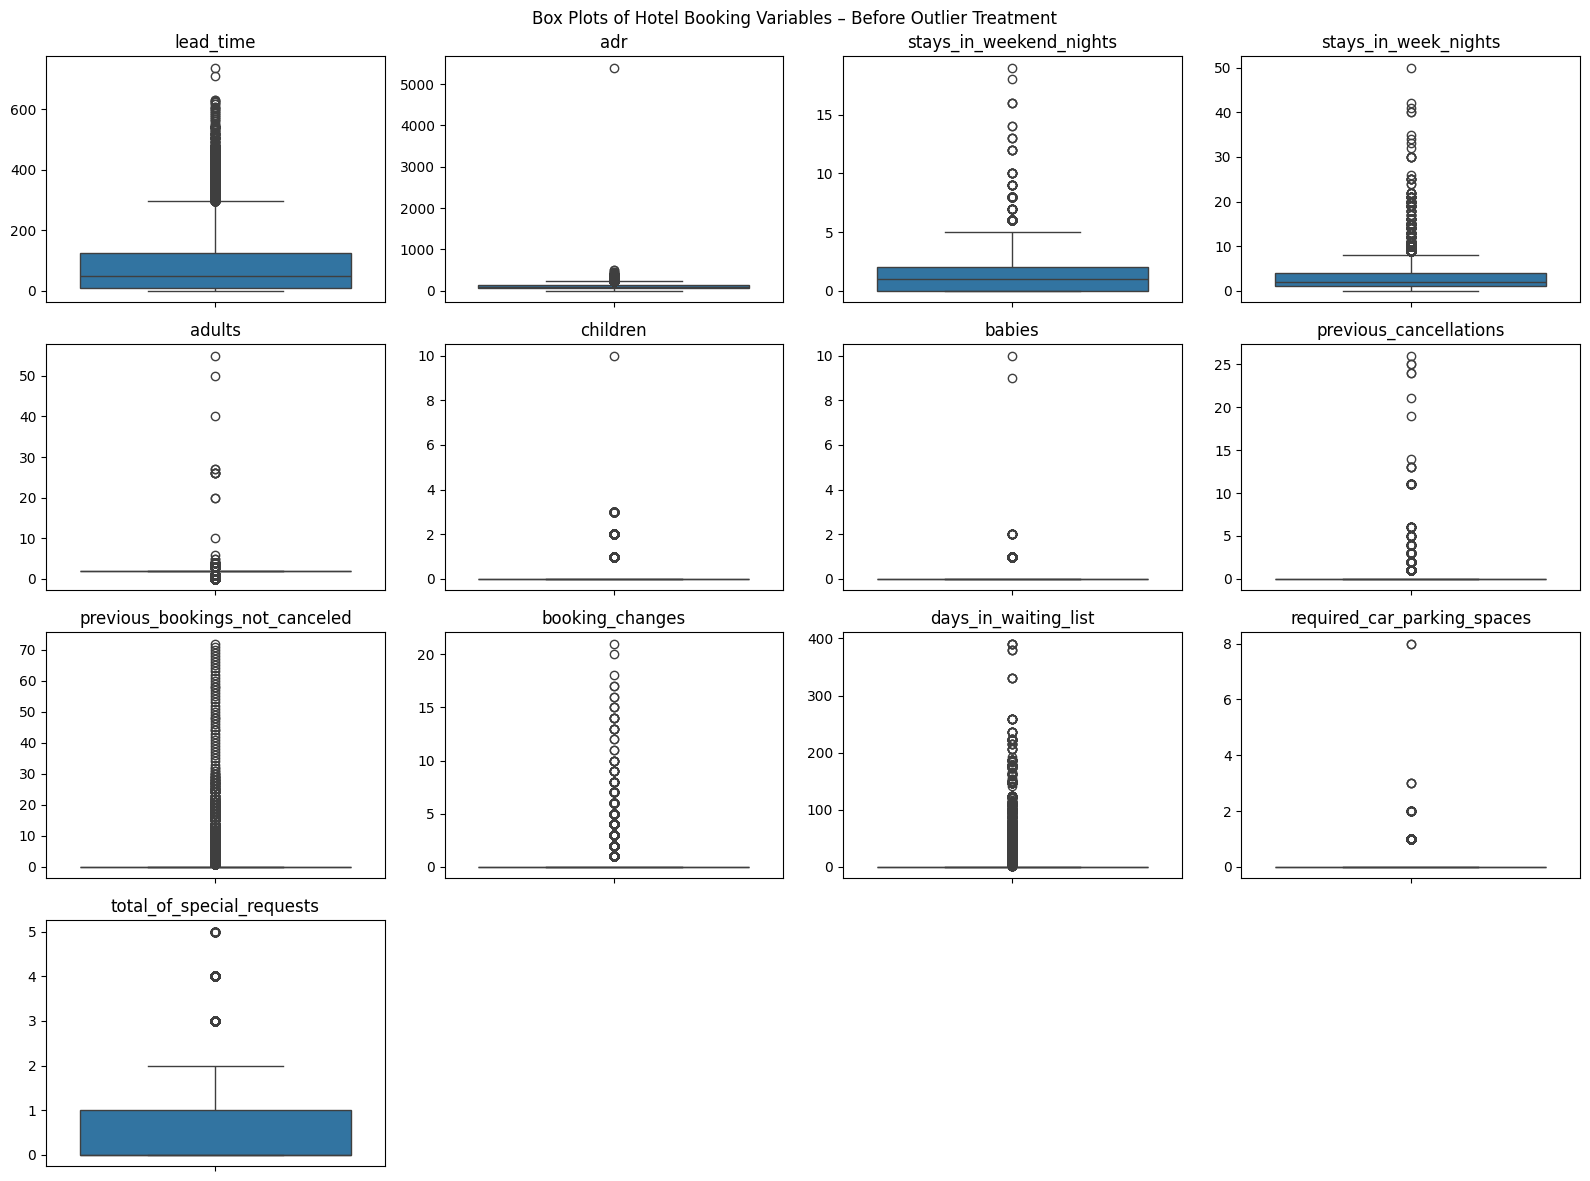

In [45]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(outlier_cols):
    sns.boxplot(y=df_final[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel("")

# Hide unused charts
for j in range(len(outlier_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Box Plots of Hotel Booking Variables – Before Outlier Treatment")
plt.tight_layout()
plt.show()


In [46]:

outlier_results = []

for col in outlier_cols:
    Q1 = df_final[col].quantile(0.25)
    Q3 = df_final[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df_final[col] < lower_limit) |
        (df_final[col] > upper_limit)
    ).sum()

    outlier_results.append({
        "Variable": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": outlier_count
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))


,Variable,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count
0,lead_time,11.0,125.0,114.0,-160.0,296.0,2396
1,adr,72.0,134.0,62.0,-21.0,227.0,2490
2,stays_in_weekend_nights,0.0,2.0,2.0,-3.0,5.0,220
3,stays_in_week_nights,1.0,4.0,3.0,-3.5,8.5,1531
4,adults,2.0,2.0,0.0,2.0,2.0,22899
5,children,0.0,0.0,0.0,0.0,0.0,8364
6,babies,0.0,0.0,0.0,0.0,0.0,914
7,previous_cancellations,0.0,0.0,0.0,0.0,0.0,1685
8,previous_bookings_not_canceled,0.0,0.0,0.0,0.0,0.0,3545
9,booking_changes,0.0,0.0,0.0,0.0,0.0,15902


In [47]:

print("Negative ADR values:")
print((df_final["adr"] < 0).sum())

print("\nZero ADR values:")
print((df_final["adr"] == 0).sum())

print("\nHighest ADR values:")
display(
    df_final[["hotel", "adr", "is_canceled"]]
    .sort_values("adr", ascending=False)
    .head(10)
)


Negative ADR values:
1

Zero ADR values:
1778

Highest ADR values:


,hotel,adr,is_canceled
48515,City Hotel,5400.00,1
111403,City Hotel,510.00,0
15083,Resort Hotel,508.00,0
103912,City Hotel,451.50,0
13142,Resort Hotel,450.00,1
13391,Resort Hotel,437.00,1
39155,Resort Hotel,426.25,0
39568,Resort Hotel,402.00,0
39118,Resort Hotel,397.38,0
13323,Resort Hotel,392.00,1


In [48]:

checks = {
    "Negative lead time": (df_final["lead_time"] < 0).sum(),
    "Negative ADR": (df_final["adr"] < 0).sum(),
    "Negative weekend nights": (df_final["stays_in_weekend_nights"] < 0).sum(),
    "Negative weekday nights": (df_final["stays_in_week_nights"] < 0).sum(),
    "Negative adults": (df_final["adults"] < 0).sum(),
    "Negative children": (df_final["children"] < 0).sum(),
    "Negative babies": (df_final["babies"] < 0).sum()
}

for issue, count in checks.items():
    print(issue, ":", count)


Negative lead time : 0
Negative ADR : 1
Negative weekend nights : 0
Negative weekday nights : 0
Negative adults : 0
Negative children : 0
Negative babies : 0


In [49]:

negative_adr = df_final[df_final["adr"] < 0]

print("Number of records with negative ADR:", len(negative_adr))

display(negative_adr.head(10))


Number of records with negative ADR: 1


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,0.0,0,BB,GBR,Groups,Direct,1,0,2,A,H,2,No Deposit,273.0,-1.0,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15


In [50]:

df_analysis = df_final.copy()

print("Final cleaned dataset:", df_final.shape)
print("Working analysis dataset:", df_analysis.shape)


Final cleaned dataset: (87396, 32)
Working analysis dataset: (87396, 32)


In [51]:

hotel_counts = df_analysis["hotel"].value_counts()

print("Number of bookings by hotel type:")
display(hotel_counts)


Number of bookings by hotel type:


,count
hotel,
City Hotel,53428
Resort Hotel,33968


In [52]:

cancellation_by_hotel = (
    df_analysis.groupby("hotel")["is_canceled"]
    .agg(["count", "sum", "mean"])
)

cancellation_by_hotel.columns = [
    "Total Bookings",
    "Canceled Bookings",
    "Cancellation Rate"
]

cancellation_by_hotel["Cancellation Rate"] = (
    cancellation_by_hotel["Cancellation Rate"] * 100
)

display(cancellation_by_hotel.round(2))


,Total Bookings,Canceled Bookings,Cancellation Rate
hotel,,,
City Hotel,53428,16049,30.04
Resort Hotel,33968,7976,23.48


In [53]:

adr_by_hotel = (
    df_analysis.groupby("hotel")["adr"]
    .agg(["mean", "median", "min", "max"])
)

display(adr_by_hotel.round(2))


,mean,median,min,max
hotel,,,,
City Hotel,110.99,105.3,0.00,5400.0
Resort Hotel,99.03,79.5,-6.38,508.0


In [54]:

hotel_performance = df_analysis.groupby("hotel").agg(
    Total_Bookings=("hotel", "count"),
    Average_Lead_Time=("lead_time", "mean"),
    Average_ADR=("adr", "mean"),
    Average_Special_Requests=("total_of_special_requests", "mean"),
    Cancellation_Rate=("is_canceled", "mean")
)

hotel_performance["Cancellation_Rate"] = (
    hotel_performance["Cancellation_Rate"] * 100
)

display(hotel_performance.round(2))


,Total_Bookings,Average_Lead_Time,Average_ADR,Average_Special_Requests,Cancellation_Rate
hotel,,,,,
City Hotel,53428,77.68,110.99,0.71,30.04
Resort Hotel,33968,83.37,99.03,0.68,23.48


In [55]:

market_counts = df_analysis["market_segment"].value_counts()

print("Bookings by Market Segment:")
display(market_counts)


Bookings by Market Segment:


,count
market_segment,
Online TA,51618
Offline TA/TO,13889
Direct,11804
Groups,4942
Corporate,4212
Complementary,702
Aviation,227
Undefined,2


In [56]:

market_cancellation = (
    df_analysis.groupby("market_segment")["is_canceled"]
    .agg(["count", "sum", "mean"])
)

market_cancellation.columns = [
    "Total Bookings",
    "Canceled Bookings",
    "Cancellation Rate"
]

market_cancellation["Cancellation Rate"] *= 100

display(market_cancellation.round(2))


,Total Bookings,Canceled Bookings,Cancellation Rate
market_segment,,,
Aviation,227,45,19.82
Complementary,702,88,12.54
Corporate,4212,510,12.11
Direct,11804,1737,14.72
Groups,4942,1335,27.01
Offline TA/TO,13889,2063,14.85
Online TA,51618,18245,35.35
Undefined,2,2,100.00


In [57]:

market_adr = (
    df_analysis.groupby("market_segment")["adr"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

display(market_adr.round(2))


,count,mean,median
market_segment,,,
Online TA,51618,118.17,110.70
Direct,11804,116.58,106.60
Aviation,227,100.17,95.00
Offline TA/TO,13889,81.76,79.05
Groups,4942,74.86,68.00
Corporate,4212,68.15,65.00
Undefined,2,15.00,15.00
Complementary,702,3.05,0.00


In [58]:

hotel_market = pd.crosstab(
    df_analysis["market_segment"],
    df_analysis["hotel"]
)

print("Bookings by Hotel Type and Market Segment:")
display(hotel_market)


Bookings by Hotel Type and Market Segment:


hotel,City Hotel,Resort Hotel
market_segment,,
Aviation,227,0
Complementary,513,189
Corporate,2227,1985
Direct,5559,6245
Groups,2635,2307
Offline TA/TO,7271,6618
Online TA,34994,16624
Undefined,2,0


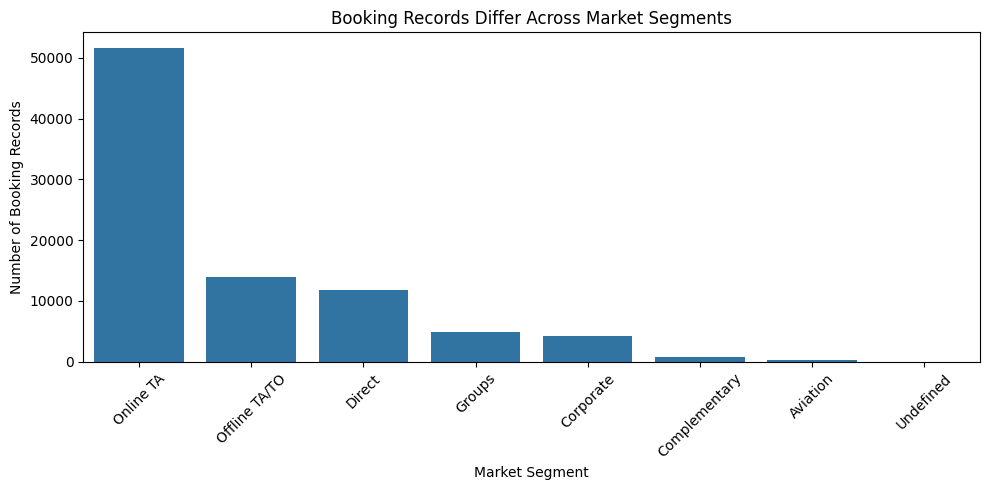

In [59]:

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_analysis,
    x="market_segment",
    order=df_analysis["market_segment"].value_counts().index
)

plt.title("Booking Records Differ Across Market Segments")
plt.xlabel("Market Segment")
plt.ylabel("Number of Booking Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [60]:

customer_counts = df_analysis["customer_type"].value_counts()

print("Bookings by Customer Type:")
display(customer_counts)


Bookings by Customer Type:


,count
customer_type,
Transient,71986
Transient-Party,11727
Contract,3139
Group,544


In [61]:

customer_cancellation = (
    df_analysis.groupby("customer_type")["is_canceled"]
    .agg(["count", "sum", "mean"])
)

customer_cancellation.columns = [
    "Total Bookings",
    "Canceled Bookings",
    "Cancellation Rate"
]

customer_cancellation["Cancellation Rate"] *= 100

display(customer_cancellation.round(2))


,Total Bookings,Canceled Bookings,Cancellation Rate
customer_type,,,
Contract,3139,512,16.31
Group,544,54,9.93
Transient,71986,21672,30.11
Transient-Party,11727,1787,15.24


In [62]:

customer_adr = (
    df_analysis.groupby("customer_type")["adr"]
    .agg(["mean", "median"])
)

display(customer_adr.round(2))


,mean,median
customer_type,,
Contract,92.75,90.90
Group,84.36,75.00
Transient,110.14,102.00
Transient-Party,87.68,81.28


In [63]:

special_requests = (
    df_analysis.groupby("customer_type")["total_of_special_requests"]
    .agg(["mean", "median", "max"])
)

display(special_requests.round(2))


,mean,median,max
customer_type,,,
Contract,0.84,1.0,5
Group,0.65,0.0,5
Transient,0.73,1.0,5
Transient-Party,0.46,0.0,5


In [64]:

special_requests = (
    df_analysis.groupby("customer_type")["total_of_special_requests"]
    .agg(["mean", "median", "max"])
)

display(special_requests.round(2))


,mean,median,max
customer_type,,,
Contract,0.84,1.0,5
Group,0.65,0.0,5
Transient,0.73,1.0,5
Transient-Party,0.46,0.0,5


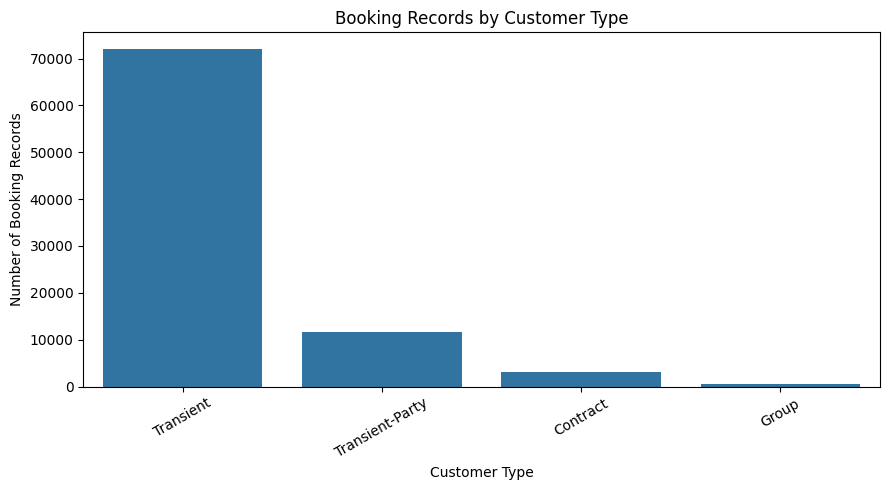

In [65]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_analysis,
    x="customer_type",
    order=df_analysis["customer_type"].value_counts().index
)

plt.title("Booking Records by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Number of Booking Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [66]:

segment_pattern = df_analysis["market_segment"].value_counts()

print("Market Segment Booking Pattern:")
display(segment_pattern)

print("\nHighest booking segment:", segment_pattern.idxmax())
print("Number of booking records:", segment_pattern.max())


Market Segment Booking Pattern:


,count
market_segment,
Online TA,51618
Offline TA/TO,13889
Direct,11804
Groups,4942
Corporate,4212
Complementary,702
Aviation,227
Undefined,2



Highest booking segment: Online TA
Number of booking records: 51618


In [67]:

hotel_cancel_rates = (
    df_analysis.groupby("hotel")["is_canceled"].mean() * 100
)

print("Cancellation Rate by Hotel:")
display(hotel_cancel_rates.round(2))

gap = hotel_cancel_rates.max() - hotel_cancel_rates.min()

print("\nDifference in cancellation rates:", round(gap, 2), "percentage points")


Cancellation Rate by Hotel:


,is_canceled
hotel,
City Hotel,30.04
Resort Hotel,23.48



Difference in cancellation rates: 6.56 percentage points


In [68]:

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_bookings = (
    df_analysis.groupby(
        ["arrival_date_year", "arrival_date_month"]
    ).size().reset_index(name="Total Bookings")
)

monthly_bookings["arrival_date_month"] = pd.Categorical(
    monthly_bookings["arrival_date_month"],
    categories=month_order,
    ordered=True
)

monthly_bookings = monthly_bookings.sort_values(
    ["arrival_date_year", "arrival_date_month"]
)

display(monthly_bookings)


,arrival_date_year,arrival_date_month,Total Bookings
2,2015,July,1674
0,2015,August,2453
5,2015,September,2839
4,2015,October,2700
3,2015,November,1665
1,2015,December,1982
10,2016,January,1849
9,2016,February,2806
13,2016,March,3831
6,2016,April,3770


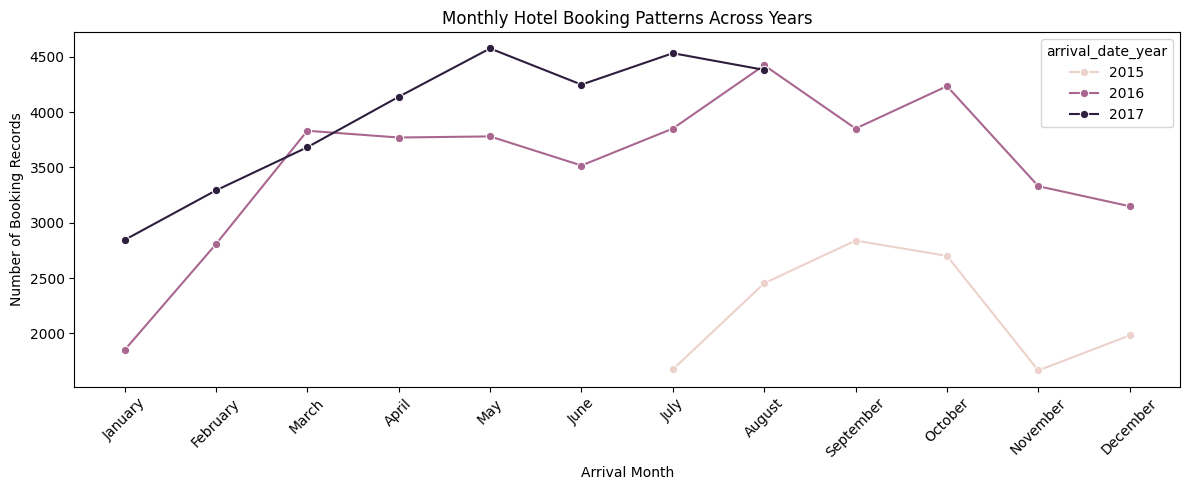

In [69]:

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_bookings,
    x="arrival_date_month",
    y="Total Bookings",
    hue="arrival_date_year",
    marker="o"
)

plt.title("Monthly Hotel Booking Patterns Across Years")
plt.xlabel("Arrival Month")
plt.ylabel("Number of Booking Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [70]:

print("Five bookings with the highest lead time:")

display(
    df_analysis[
        ["hotel", "lead_time", "adr", "market_segment"]
    ].sort_values(
        "lead_time", ascending=False
    ).head(5)
)


Five bookings with the highest lead time:


,hotel,lead_time,adr,market_segment
1,Resort Hotel,737,0.0,Direct
4182,Resort Hotel,709,68.0,Direct
65237,City Hotel,629,62.0,Groups
65231,City Hotel,629,59.0,Groups
60173,City Hotel,626,62.8,Groups


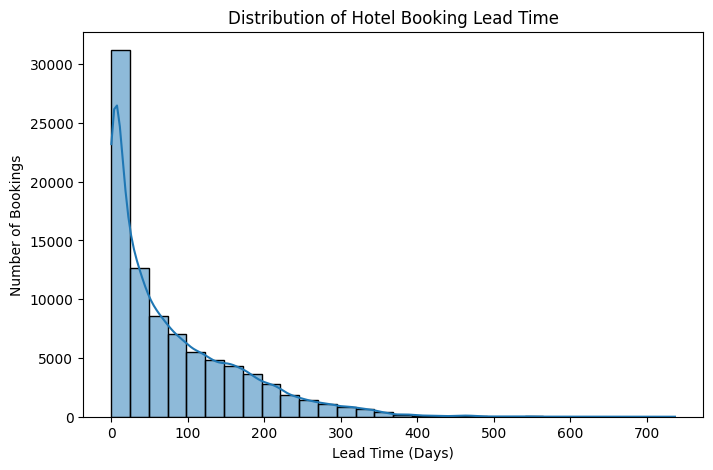

In [71]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df_final, x="lead_time", bins=30, kde=True)

plt.title("Distribution of Hotel Booking Lead Time")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Number of Bookings")

plt.show()


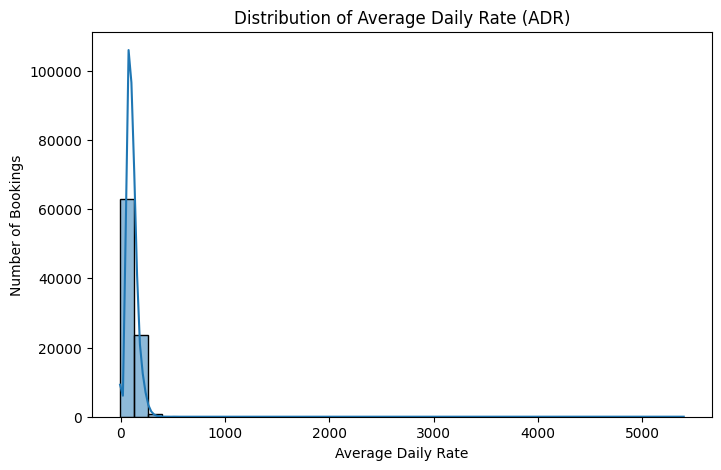

In [72]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df_final, x="adr", bins=40, kde=True)

plt.title("Distribution of Average Daily Rate (ADR)")
plt.xlabel("Average Daily Rate")
plt.ylabel("Number of Bookings")

plt.show()


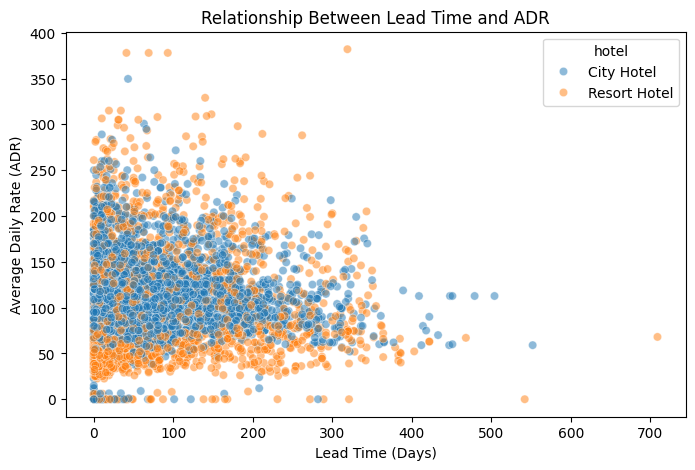

In [73]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_final.sample(5000, random_state=42),
    x="lead_time",
    y="adr",
    hue="hotel",
    alpha=0.5
)

plt.title("Relationship Between Lead Time and ADR")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Average Daily Rate (ADR)")

plt.show()


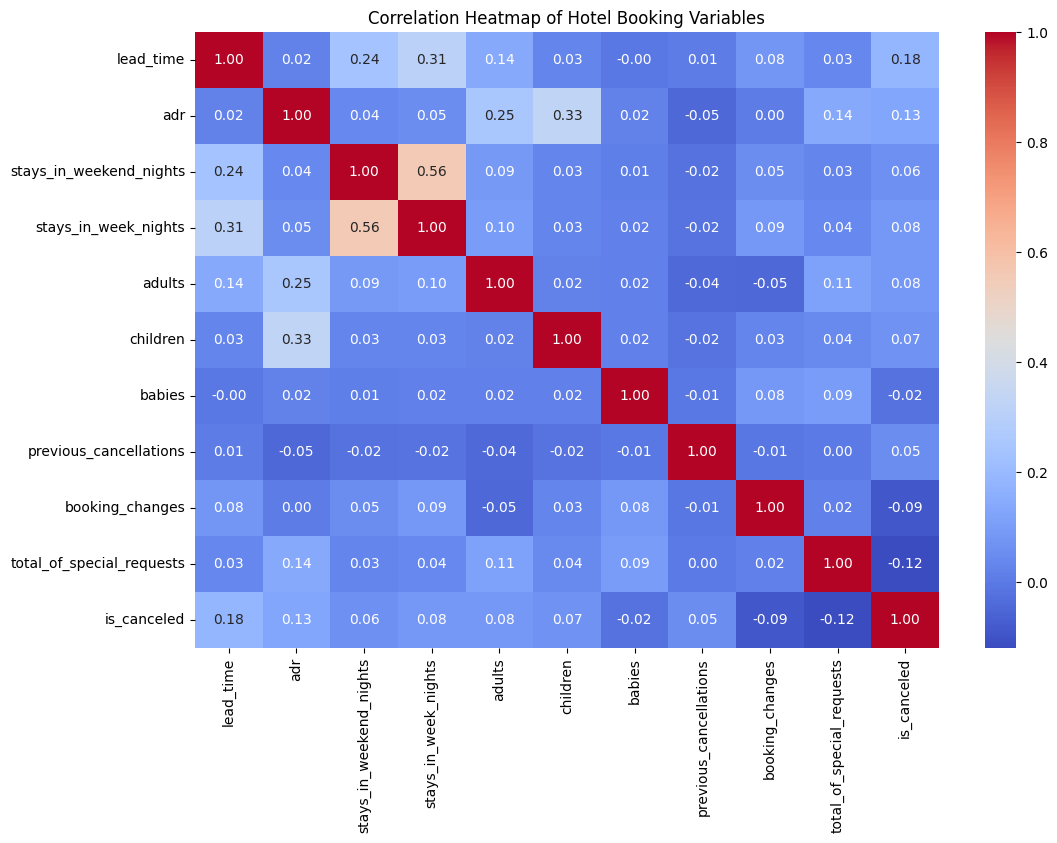

In [74]:

correlation_columns = [
    "lead_time",
    "adr",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "booking_changes",
    "total_of_special_requests",
    "is_canceled"
]

correlation_matrix = df_final[correlation_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Hotel Booking Variables")
plt.show()


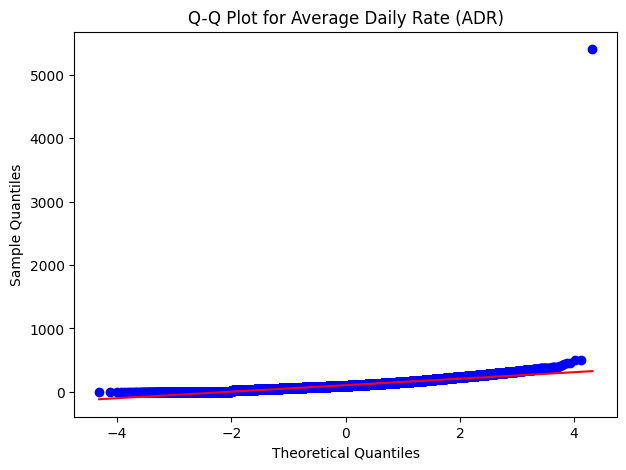

In [75]:

plt.figure(figsize=(7, 5))

stats.probplot(df_final["adr"], dist="norm", plot=plt)

plt.title("Q-Q Plot for Average Daily Rate (ADR)")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")

plt.show()


In [76]:

correlation_value = df_final["lead_time"].corr(df_final["adr"])

print("Correlation between Lead Time and ADR:", round(correlation_value, 3))

if correlation_value > 0:
    print("There is a positive relationship between Lead Time and ADR.")
elif correlation_value < 0:
    print("There is a negative relationship between Lead Time and ADR.")
else:
    print("There is no linear relationship between Lead Time and ADR.")


Correlation between Lead Time and ADR: 0.024
There is a positive relationship between Lead Time and ADR.


In [77]:

adr_comparison = df_final.groupby("hotel")["adr"].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

print("ADR Comparison Between City Hotel and Resort Hotel:")
display(adr_comparison)


ADR Comparison Between City Hotel and Resort Hotel:


,count,mean,median,min,max,std
hotel,,,,,,
City Hotel,53428,110.985944,105.3,0.00,5400.0,48.062518
Resort Hotel,33968,99.025346,79.5,-6.38,508.0,63.766782


In [78]:

market_cancellation = df_final.groupby("market_segment").agg(
    total_bookings=("is_canceled", "count"),
    canceled_bookings=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

market_cancellation["cancellation_rate"] = (
    market_cancellation["cancellation_rate"] * 100
)

market_cancellation = market_cancellation.sort_values(
    by="cancellation_rate",
    ascending=False
)

display(market_cancellation.round(2))


,total_bookings,canceled_bookings,cancellation_rate
market_segment,,,
Undefined,2,2,100.00
Online TA,51618,18245,35.35
Groups,4942,1335,27.01
Aviation,227,45,19.82
Offline TA/TO,13889,2063,14.85
Direct,11804,1737,14.72
Complementary,702,88,12.54
Corporate,4212,510,12.11


,count,mean,median
market_segment,,,
Online TA,51618,118.17,110.70
Direct,11804,116.58,106.60
Aviation,227,100.17,95.00
Offline TA/TO,13889,81.76,79.05
Groups,4942,74.86,68.00
Corporate,4212,68.15,65.00
Undefined,2,15.00,15.00
Complementary,702,3.05,0.00


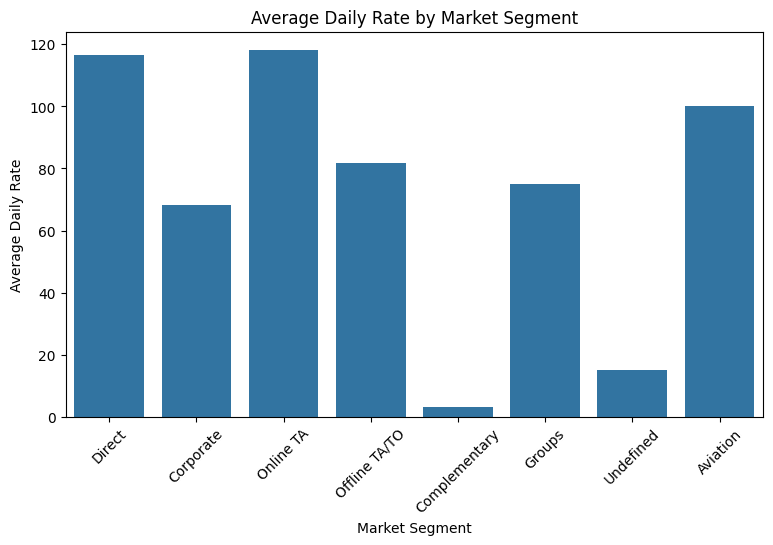

In [79]:

market_adr = df_final.groupby("market_segment")["adr"].agg(
    ["count", "mean", "median"]
)

market_adr = market_adr.sort_values(
    by="mean",
    ascending=False
)

display(market_adr.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_final,
    x="market_segment",
    y="adr",
    errorbar=None
)

plt.title("Average Daily Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Average Daily Rate")
plt.xticks(rotation=45)

plt.show()


,count,mean,median
market_segment,,,
Online TA,51618,118.17,110.70
Direct,11804,116.58,106.60
Aviation,227,100.17,95.00
Offline TA/TO,13889,81.76,79.05
Groups,4942,74.86,68.00
Corporate,4212,68.15,65.00
Undefined,2,15.00,15.00
Complementary,702,3.05,0.00


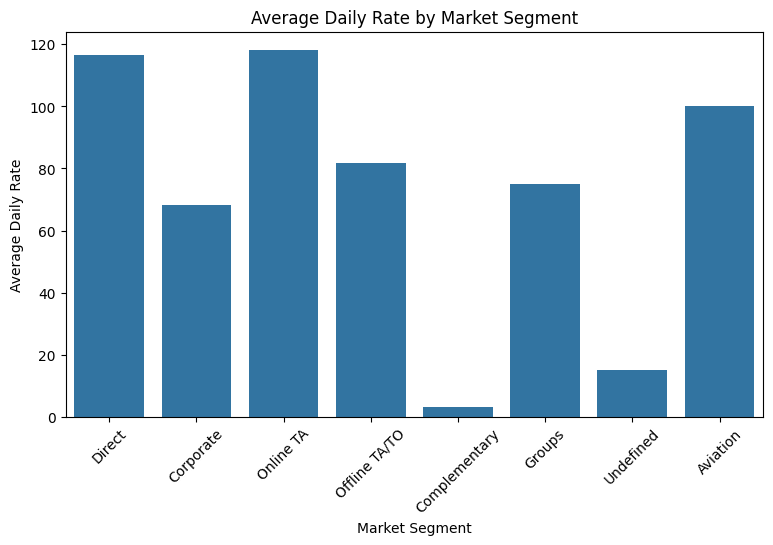

In [80]:

market_adr = df_final.groupby("market_segment")["adr"].agg(
    ["count", "mean", "median"]
)

market_adr = market_adr.sort_values(
    by="mean",
    ascending=False
)

display(market_adr.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_final,
    x="market_segment",
    y="adr",
    errorbar=None
)

plt.title("Average Daily Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Average Daily Rate")
plt.xticks(rotation=45)

plt.show()


,total_bookings,canceled_bookings,cancellation_rate
hotel,,,
City Hotel,53428,16049,30.04
Resort Hotel,33968,7976,23.48


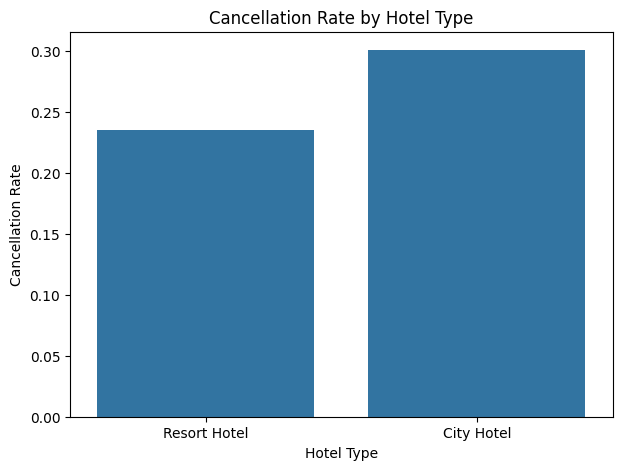

In [81]:

hotel_cancellation = df_final.groupby("hotel").agg(
    total_bookings=("is_canceled", "count"),
    canceled_bookings=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

hotel_cancellation["cancellation_rate"] = (
    hotel_cancellation["cancellation_rate"] * 100
)

display(hotel_cancellation.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df_final,
    x="hotel",
    y="is_canceled",
    errorbar=None
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate")

plt.show()


,total_bookings,canceled_bookings,cancellation_rate
total_of_special_requests,,,
0,43894,14574,33.20
1,29017,6503,22.41
2,11812,2515,21.29
3,2317,397,17.13
4,320,34,10.62
5,36,2,5.56


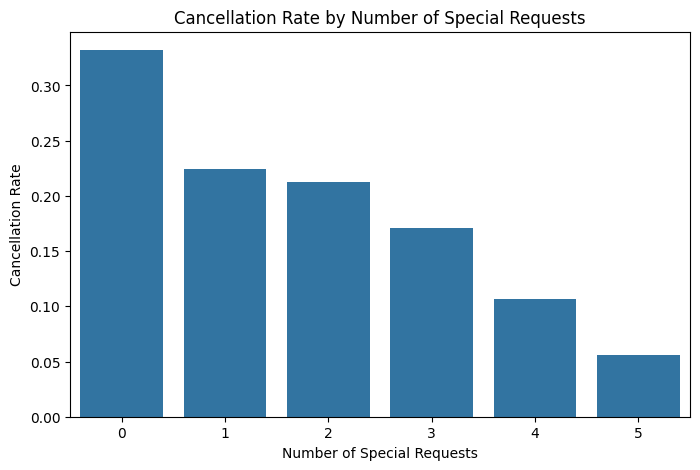

In [82]:

special_request_analysis = df_final.groupby(
    "total_of_special_requests"
).agg(
    total_bookings=("is_canceled", "count"),
    canceled_bookings=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

special_request_analysis["cancellation_rate"] = (
    special_request_analysis["cancellation_rate"] * 100
)

display(special_request_analysis.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_final,
    x="total_of_special_requests",
    y="is_canceled",
    errorbar=None
)

plt.title("Cancellation Rate by Number of Special Requests")
plt.xlabel("Number of Special Requests")
plt.ylabel("Cancellation Rate")

plt.show()


In [83]:

customer_cancellation = df_final.groupby("customer_type").agg(
    total_bookings=("is_canceled", "count"),
    canceled_bookings=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

customer_cancellation["cancellation_rate"] *= 100

display(customer_cancellation.round(2))


,total_bookings,canceled_bookings,cancellation_rate
customer_type,,,
Contract,3139,512,16.31
Group,544,54,9.93
Transient,71986,21672,30.11
Transient-Party,11727,1787,15.24


In [84]:

monthly_bookings = df_final.groupby(
    ["arrival_date_year", "arrival_date_month"]
).size().reset_index(name="total_bookings")

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_bookings["arrival_date_month"] = pd.Categorical(
    monthly_bookings["arrival_date_month"],
    categories=month_order,
    ordered=True
)

monthly_bookings = monthly_bookings.sort_values(
    ["arrival_date_year", "arrival_date_month"]
)

display(monthly_bookings)


,arrival_date_year,arrival_date_month,total_bookings
2,2015,July,1674
0,2015,August,2453
5,2015,September,2839
4,2015,October,2700
3,2015,November,1665
1,2015,December,1982
10,2016,January,1849
9,2016,February,2806
13,2016,March,3831
6,2016,April,3770


,count
country,
PRT,27453
GBR,10433
FRA,8837
ESP,7252
DEU,5387
ITA,3066
IRL,3016
BEL,2081
BRA,1995


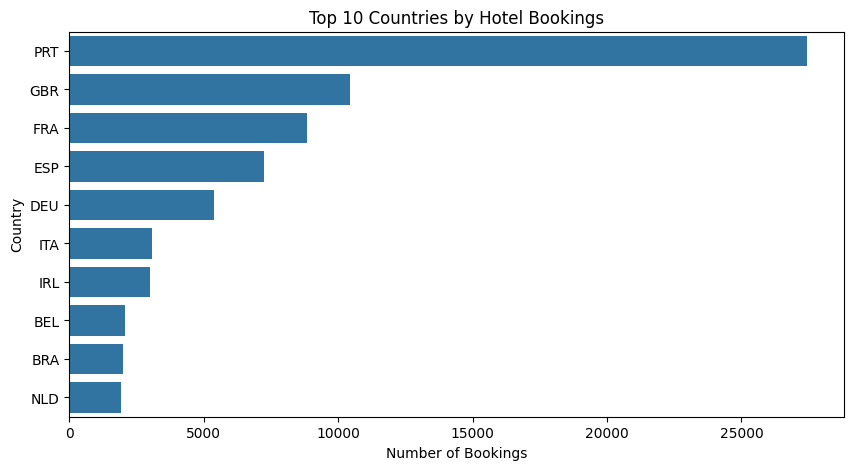

In [85]:

top_countries = (
    df_final[df_final["country"] != "Unknown"]
    ["country"]
    .value_counts()
    .head(10)
)

display(top_countries)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_countries.values, y=top_countries.index)

plt.title("Top 10 Countries by Hotel Bookings")
plt.xlabel("Number of Bookings")
plt.ylabel("Country")
plt.show()


In [86]:

booking_change_analysis = df_final.groupby("booking_changes").agg(
    total_bookings=("is_canceled", "count"),
    cancellation_rate=("is_canceled", "mean")
)

booking_change_analysis["cancellation_rate"] *= 100

display(booking_change_analysis.round(2))


,total_bookings,cancellation_rate
booking_changes,,
0,71494,30.17
1,10902,13.86
2,3508,20.07
3,875,14.97
4,356,17.70
5,116,17.24
6,59,28.81
7,31,9.68
8,17,23.53


,average_special_requests,total_special_requests
hotel,,
City Hotel,0.71,37987
Resort Hotel,0.68,23065


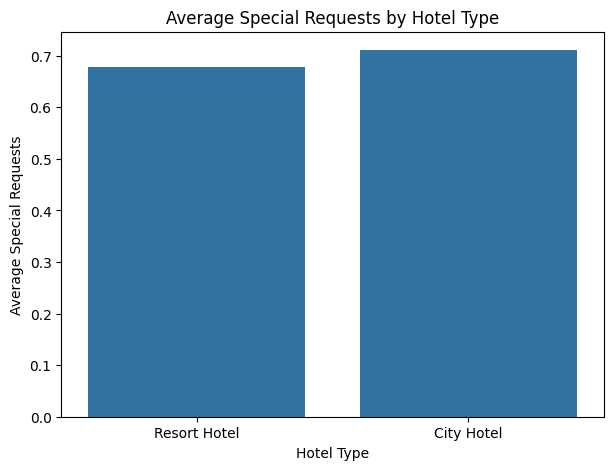

In [87]:

hotel_requests = df_final.groupby("hotel").agg(
    average_special_requests=("total_of_special_requests", "mean"),
    total_special_requests=("total_of_special_requests", "sum")
)

display(hotel_requests.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(
    data=df_final,
    x="hotel",
    y="total_of_special_requests",
    errorbar=None
)

plt.title("Average Special Requests by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Average Special Requests")
plt.show()


,average_special_requests,total_special_requests
hotel,,
City Hotel,0.71,37987
Resort Hotel,0.68,23065


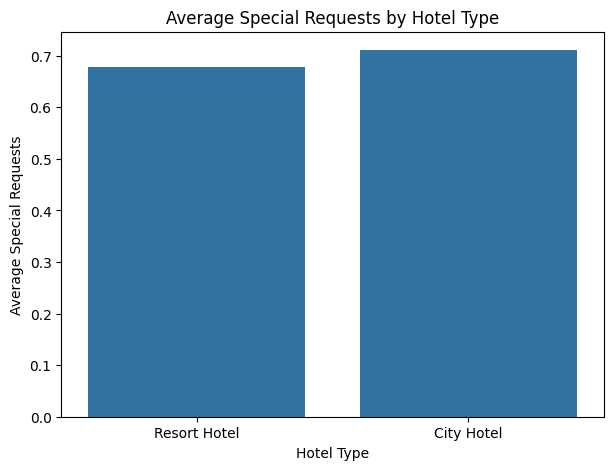

In [88]:

hotel_requests = df_final.groupby("hotel").agg(
    average_special_requests=("total_of_special_requests", "mean"),
    total_special_requests=("total_of_special_requests", "sum")
)

display(hotel_requests.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(
    data=df_final,
    x="hotel",
    y="total_of_special_requests",
    errorbar=None
)

plt.title("Average Special Requests by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Average Special Requests")
plt.show()


Business Question 1: Does booking early or late affect cancellation rates?

In [89]:

df_final["lead_time_category"] = pd.cut(
    df_final["lead_time"],
    bins=[-1, 30, 90, 180, float("inf")],
    labels=["0-30 days", "31-90 days", "91-180 days", "Above 180 days"]
)

lead_time_cancellation = df_final.groupby(
    "lead_time_category", observed=False
).agg(
    total_bookings=("is_canceled", "count"),
    cancellation_rate=("is_canceled", "mean")
)

lead_time_cancellation["cancellation_rate"] *= 100

display(lead_time_cancellation.round(2))


,total_bookings,cancellation_rate
lead_time_category,,
0-30 days,34644,16.42
31-90 days,22744,32.01
91-180 days,18243,34.98
Above 180 days,11765,39.74


Business Question 2: Which deposit type has the highest cancellation rate?

In [90]:

deposit_analysis = df_final.groupby("deposit_type").agg(
    total_bookings=("is_canceled", "count"),
    canceled_bookings=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

deposit_analysis["cancellation_rate"] *= 100

display(deposit_analysis.sort_values(
    "cancellation_rate", ascending=False
).round(2))


,total_bookings,canceled_bookings,cancellation_rate
deposit_type,,,
Non Refund,1038,983,94.70
No Deposit,86251,23016,26.68
Refundable,107,26,24.30


Business Question 3: Do repeated guests cancel less often?

In [91]:

repeat_guest_analysis = df_final.groupby("is_repeated_guest").agg(
    total_bookings=("is_canceled", "count"),
    canceled_bookings=("is_canceled", "sum"),
    cancellation_rate=("is_canceled", "mean")
)

repeat_guest_analysis["cancellation_rate"] *= 100

display(repeat_guest_analysis.round(2))


,total_bookings,canceled_bookings,cancellation_rate
is_repeated_guest,,,
0,83981,23764,28.30
1,3415,261,7.64


Business Question 4: Which distribution channel contributes the most bookings?

In [92]:

channel_analysis = df_final.groupby("distribution_channel").agg(
    total_bookings=("is_canceled", "count"),
    average_adr=("adr", "mean"),
    cancellation_rate=("is_canceled", "mean")
)

channel_analysis["cancellation_rate"] *= 100

channel_analysis = channel_analysis.sort_values(
    "total_bookings", ascending=False
)

display(channel_analysis.round(2))


,total_bookings,average_adr,cancellation_rate
distribution_channel,,,
TA/TO,69141,108.56,30.97
Direct,12988,109.13,14.82
Corporate,5081,68.52,12.75
GDS,181,120.32,19.89
Undefined,5,46.24,80.00


Business Question 5: Which hotel has greater demand for parking?

In [93]:

parking_analysis = df_final.groupby("hotel").agg(
    total_bookings=("hotel", "count"),
    bookings_with_parking=("required_car_parking_spaces",
                           lambda x: (x > 0).sum()),
    total_parking_spaces_requested=("required_car_parking_spaces", "sum")
)

parking_analysis["parking_request_percentage"] = (
    parking_analysis["bookings_with_parking"] /
    parking_analysis["total_bookings"] * 100
)

display(parking_analysis.round(2))


,total_bookings,bookings_with_parking,total_parking_spaces_requested,parking_request_percentage
hotel,,,,
City Hotel,53428,1896,1903,3.55
Resort Hotel,33968,5417,5458,15.95


In [94]:

highest_cancellation_segment = market_cancellation[
    "cancellation_rate"
].idxmax()

highest_cancellation_rate = market_cancellation[
    "cancellation_rate"
].max()

print("Business Finding 1")
print("Market segment with highest cancellation:",
      highest_cancellation_segment)
print("Cancellation rate:",
      round(highest_cancellation_rate, 2), "%")


Business Finding 1
Market segment with highest cancellation: Undefined
Cancellation rate: 100.0 %


In [95]:

highest_adr_hotel = adr_comparison["mean"].idxmax()
highest_adr_value = adr_comparison["mean"].max()

print("Business Finding 2")
print("Hotel with highest average room rate:", highest_adr_hotel)
print("Average Daily Rate:", round(highest_adr_value, 2))


Business Finding 2
Hotel with highest average room rate: City Hotel
Average Daily Rate: 110.99


In [96]:

highest_customer_cancellation = customer_cancellation[
    "cancellation_rate"
].idxmax()

highest_customer_rate = customer_cancellation[
    "cancellation_rate"
].max()

print("Business Finding 3")
print("Customer type with highest cancellation:",
      highest_customer_cancellation)
print("Cancellation rate:",
      round(highest_customer_rate, 2), "%")


Business Finding 3
Customer type with highest cancellation: Transient
Cancellation rate: 30.11 %


In [97]:

top_channel = channel_analysis["total_bookings"].idxmax()
top_channel_bookings = channel_analysis["total_bookings"].max()

print("Business Finding 4")
print("Most important distribution channel:", top_channel)
print("Total bookings:", top_channel_bookings)


Business Finding 4
Most important distribution channel: TA/TO
Total bookings: 69141


In [98]:

highest_parking_hotel = parking_analysis[
    "parking_request_percentage"
].idxmax()

highest_parking_percentage = parking_analysis[
    "parking_request_percentage"
].max()

print("Business Finding 5")
print("Hotel with higher parking demand:",
      highest_parking_hotel)
print("Percentage of bookings requesting parking:",
      round(highest_parking_percentage, 2), "%")


Business Finding 5
Hotel with higher parking demand: Resort Hotel
Percentage of bookings requesting parking: 15.95 %


In [99]:

hotel_summary = df_final.groupby("hotel").agg(
    total_bookings=("hotel", "count"),
    average_adr=("adr", "mean"),
    cancellation_rate=("is_canceled", "mean"),
    average_lead_time=("lead_time", "mean")
)

hotel_summary["cancellation_rate"] *= 100

display(hotel_summary.round(2))


,total_bookings,average_adr,cancellation_rate,average_lead_time
hotel,,,,
City Hotel,53428,110.99,30.04,77.68
Resort Hotel,33968,99.03,23.48,83.37


In [100]:

busiest_months = (
    df_final.groupby("arrival_date_month")
    .size()
    .sort_values(ascending=False)
)

display(busiest_months)

print("Busiest month:", busiest_months.idxmax())
print("Total bookings:", busiest_months.max())


,0
arrival_date_month,
August,11257
July,10057
May,8355
April,7908
June,7765
March,7513
October,6934
September,6690
February,6098


Busiest month: August
Total bookings: 11257


In [101]:

guest_analysis = df_final.groupby("is_repeated_guest").agg(
    total_bookings=("is_repeated_guest", "count"),
    average_adr=("adr", "mean"),
    average_special_requests=("total_of_special_requests", "mean"),
    cancellation_rate=("is_canceled", "mean")
)

guest_analysis["cancellation_rate"] *= 100

display(guest_analysis.round(2))


,total_bookings,average_adr,average_special_requests,cancellation_rate
is_repeated_guest,,,,
0,83981,108.04,0.70,28.30
1,3415,64.59,0.69,7.64


customer_type,Contract,Group,Transient,Transient-Party
hotel,,,,
City Hotel,1471,271,44641,7045
Resort Hotel,1668,273,27345,4682


<Figure size 900x500 with 0 Axes>

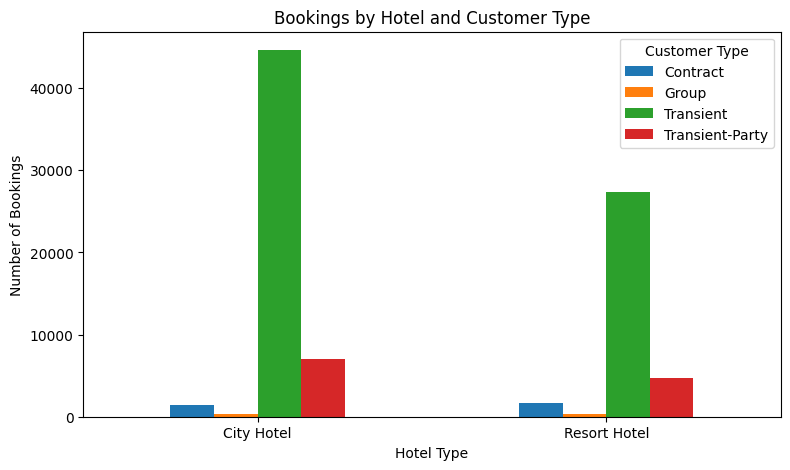

In [102]:

hotel_customer_analysis = pd.crosstab(
    df_final["hotel"],
    df_final["customer_type"]
)

display(hotel_customer_analysis)

plt.figure(figsize=(9, 5))

hotel_customer_analysis.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Bookings by Hotel and Customer Type")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=0)
plt.legend(title="Customer Type")
plt.show()


In [103]:

guest_analysis = df_final.groupby("is_repeated_guest").agg(
    total_bookings=("is_repeated_guest", "count"),
    average_adr=("adr", "mean"),
    average_special_requests=("total_of_special_requests", "mean"),
    cancellation_rate=("is_canceled", "mean")
)

guest_analysis["cancellation_rate"] *= 100

display(guest_analysis.round(2))


,total_bookings,average_adr,average_special_requests,cancellation_rate
is_repeated_guest,,,,
0,83981,108.04,0.70,28.30
1,3415,64.59,0.69,7.64


customer_type,Contract,Group,Transient,Transient-Party
hotel,,,,
City Hotel,1471,271,44641,7045
Resort Hotel,1668,273,27345,4682


<Figure size 900x500 with 0 Axes>

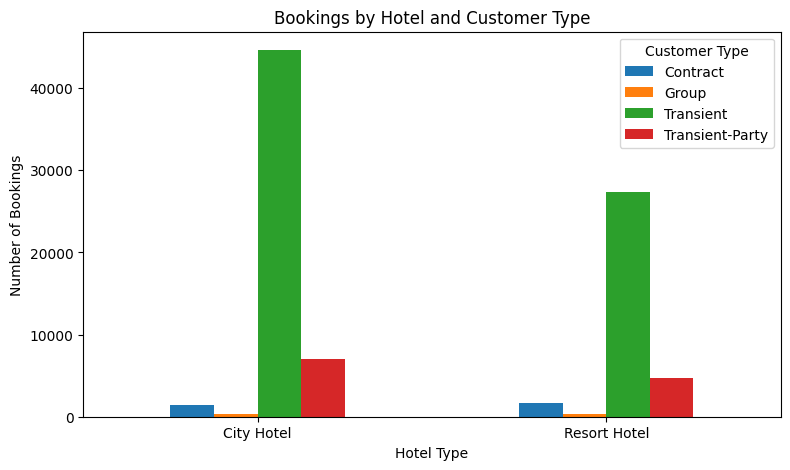

In [104]:

hotel_customer_analysis = pd.crosstab(
    df_final["hotel"],
    df_final["customer_type"]
)

display(hotel_customer_analysis)

plt.figure(figsize=(9, 5))

hotel_customer_analysis.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Bookings by Hotel and Customer Type")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=0)
plt.legend(title="Customer Type")
plt.show()


In [105]:

risk_analysis = df_final.copy()

risk_analysis["high_lead_time"] = (
    risk_analysis["lead_time"] > 180
)

risk_analysis["high_cancellation_risk_group"] = (
    (risk_analysis["high_lead_time"]) &
    (risk_analysis["is_canceled"] == 1)
)

high_risk_summary = risk_analysis.groupby("hotel").agg(
    total_bookings=("hotel", "count"),
    high_lead_time_bookings=("high_lead_time", "sum"),
    canceled_high_lead_time_bookings=(
        "high_cancellation_risk_group", "sum"
    )
)

display(high_risk_summary)


,total_bookings,high_lead_time_bookings,canceled_high_lead_time_bookings
hotel,,,
City Hotel,53428,6253,2807
Resort Hotel,33968,5512,1868


In [106]:

print("FINAL DATASET QUALITY REPORT")

print("Number of Rows:", df_final.shape[0])
print("Number of Columns:", df_final.shape[1])

print("Duplicate Rows:", df_final.duplicated().sum())

print("\nMissing Values:")
print(df_final.isnull().sum().sum())

print("\nDataset Information:")
df_final.info()


FINAL DATASET QUALITY REPORT
Number of Rows: 87396
Number of Columns: 33
Duplicate Rows: 0

Missing Values:
0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 87396 entries, 0 to 119389
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   hotel                           87396 non-null  object  
 1   is_canceled                     87396 non-null  int64   
 2   lead_time                       87396 non-null  int64   
 3   arrival_date_year               87396 non-null  int64   
 4   arrival_date_month              87396 non-null  object  
 5   arrival_date_week_number        87396 non-null  int64   
 6   arrival_date_day_of_month       87396 non-null  int64   
 7   stays_in_weekend_nights         87396 non-null  int64   
 8   stays_in_week_nights            87396 non-null  int64   
 9   adults                          87396 non-null  int64   
 10  children      

In [107]:

df_final.to_csv(
    "Hotel_Booking_Final_Cleaned.csv",
    index=False
)

print("Final cleaned dataset saved successfully!")


Final cleaned dataset saved successfully!
